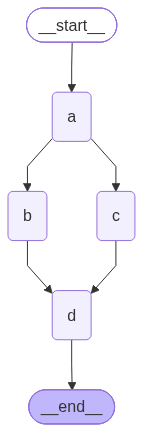

In [5]:

from operator import add
from typing import TypedDict, Annotated

from IPython.core.display import Image
from langgraph.constants import START, END
from langgraph.graph import StateGraph


# State
class ParallelState(TypedDict):
    nodes: Annotated[list[str], add]  # 使用自定义Reducer


# Node
def node_a(state: ParallelState):
    print(f"node_a，state: {state}")
    return {
        "nodes": ["a"],
    }


def node_b(state: ParallelState):
    print(f"node_b，state: {state}")
    return {
        "nodes": ["b"],
    }


def node_c(state: ParallelState):
    print(f"node_c，state: {state}")
    return {
        "nodes": ["c"],
    }


def node_d(state: ParallelState):
    print(f"node_d，state: {state}")
    return {
        "nodes": ["d"],
    }


# Edge
builder = StateGraph(ParallelState)

builder.add_node("a", node_a)
builder.add_node("b", node_b)
builder.add_node("c", node_c)
builder.add_node("d", node_d)

builder.add_edge(START, "a")
builder.add_edge("a", "b")
builder.add_edge("a", "c")
builder.add_edge("b", "d")
builder.add_edge("c", "d")
builder.add_edge("d", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [6]:
res_state = graph.invoke({})
print(f"res_state = {res_state}")

node_a，state: {'nodes': []}
node_b，state: {'nodes': ['a']}
node_c，state: {'nodes': ['a']}
node_d，state: {'nodes': ['a', 'b', 'c']}
res_state = {'nodes': ['a', 'b', 'c', 'd']}
